/tmp/ipykernel_1971566/2130612292.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  count_df = adata_HD.obs.groupby(["batch", "type"]).size().reset_index(name="count")
/tmp/ipykernel_1971566/2130612292.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  count_df["Proportion"] = count_df.groupby("batch")["count"].transform(lambda x: x / x.sum() * 100)


<Figure size 1000x600 with 0 Axes>

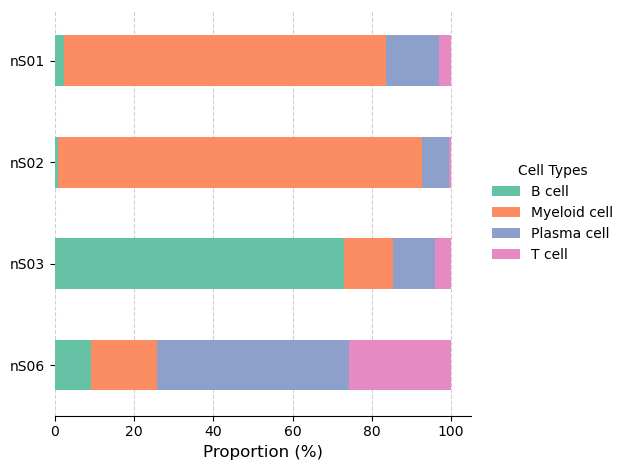

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scanpy as sc
# ================= 1. 配置区域 =================
adata_HD = sc.read("../h5ad/adata_HD.h5ad")
# 定义想要保留的细胞类型列表
target_types = ["T cell", "B cell", "Myeloid cell", "Plasma cell"] 
# ===============================================

# ================= 2. 数据预处理与筛选 =================
# 先分组计算数量
count_df = adata_HD.obs.groupby(["batch", "type"]).size().reset_index(name="count")

# 筛选出目标细胞类型
count_df = count_df[count_df["type"].isin(target_types)]

# 重新计算比例
count_df["Proportion"] = count_df.groupby("batch")["count"].transform(lambda x: x / x.sum() * 100)

# 透视数据
pivot_df = count_df.pivot(index="batch", columns="type", values="Proportion").fillna(0)

# 这行代码会确保图表顺序
pivot_df = pivot_df.loc[list(["nS01","nS02","nS03","nS06"])[::-1]]
# =====================================================

# 3. 设置画布
plt.figure(figsize=(10, 6))

# 4. 定义配色
palette = sns.color_palette("Set2", len(pivot_df.columns))

# 5. 绘图
ax = pivot_df.plot(kind='barh', stacked=True, color=palette, edgecolor='none', linewidth=0)

# 6. 美化细节
plt.xlabel("Proportion (%)", fontsize=12)
plt.ylabel("") 

# 7. 调整图例（右侧垂直居中）
plt.legend(title="Cell Types", bbox_to_anchor=(1.02, 0.5), loc='center left', frameon=False)

# 8. 去掉边框
sns.despine(left=True, bottom=False)

# 9. 网格线
ax.xaxis.grid(True, linestyle='--', alpha=0.6)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()